Model Setup

In [ ]:
import os
import cv2
import torch
import random
import numpy as np
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [ ]:
!pip install plotly
import plotly.graph_objects as go


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
DATASET_PATH = "/content/drive/MyDrive/tennis - data"

classes = ["Backhand", "Forehand", "NoStroke", "Serves"]
class_to_idx = {cls: idx for idx, cls in enumerate(classes)}

print("Class mapping:", class_to_idx)
print("Dataset path:", DATASET_PATH)



Class mapping: {'Backhand': 0, 'Forehand': 1, 'NoStroke': 2, 'Serves': 3}
Dataset path: /content/drive/MyDrive/tennis - data


In [ ]:
for cls in classes:
    folder = os.path.join(DATASET_PATH, cls)
    print(cls, "→", len(os.listdir(folder)), "videos")


Backhand → 21 videos
Forehand → 21 videos
NoStroke → 41 videos
Serves → 21 videos


In [ ]:
import cv2
import matplotlib.pyplot as plt
import random

def show_sample_frames_per_class(
    dataset_path,
    classes,
    num_frames=4,
    resize=(224, 224)
):
    fig, axes = plt.subplots(len(classes), num_frames, figsize=(num_frames * 3, len(classes) * 3))

    for row, cls in enumerate(classes):
        cls_folder = os.path.join(dataset_path, cls)
        video_files = [f for f in os.listdir(cls_folder) if f.endswith(".mp4")]

        video_path = os.path.join(cls_folder, random.choice(video_files))
        cap = cv2.VideoCapture(video_path)

        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        frame_indices = [int(i * total_frames / num_frames) for i in range(num_frames)]

        frames = []
        for idx in frame_indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
            ret, frame = cap.read()
            if ret:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                frame = cv2.resize(frame, resize)
                frames.append(frame)
        cap.release()

        for col in range(num_frames):
            ax = axes[row, col]
            ax.imshow(frames[col])
            ax.axis("off")
            if col == 0:
                ax.set_ylabel(cls, fontsize=12)

    plt.suptitle("Sample Frames from Each Class", fontsize=14)
    plt.tight_layout()
    plt.show()


In [ ]:
def load_video_frames(path, num_frames=16, resize=(112, 112)):
    """
    Extracts 'num_frames' evenly spaced frames from a video
     Then returns: numpy array of shape (num_frames, H, W, 3)
    """

    cap = cv2.VideoCapture(path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # we want evenly spaced frame numbers - uniform sampling
    indices = np.linspace(0, total_frames - 1, num_frames).astype(int)

    frames = []
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame = cap.read()

        if not ret:
            continue

        # we are just matching pytorch colour format nothing special
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        # we need to resize as neural networks require fixed input dimensions
        frame = cv2.resize(frame, resize)

        # Normalisation - stabalises gradient descent
        frame = frame.astype(np.float32) / 255.0

        frames.append(frame)

    cap.release()

    # if video is too short can duplicate
    if len(frames) < num_frames:
        while len(frames) < num_frames:
            frames.append(frames[-1])

    return np.array(frames)


In [ ]:
class TennisVideoDataset(Dataset):
    def __init__(self, video_paths, labels, num_frames=16):
        """
        This is the custom dataset for the tennis stroke videos
        the class recieves a list of videos
        so when an item is requested it loads the corresponding videos and
        Returns the frames and their label
        """
        self.video_paths = video_paths
        self.labels = labels
        self.num_frames = num_frames


        self.transform = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize((112, 112)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

    def __len__(self):
        return len(self.video_paths)

    def __getitem__(self, idx):
        video_path = self.video_paths[idx]
        label = self.labels[idx]

        # Extracts a fixed set of frames
        frames = load_video_frames(video_path, num_frames=self.num_frames)



        processed_frames = []
        for f in frames:
            f = self.transform(f)
            processed_frames.append(f)

        # Convert list → tensor
        frames = torch.stack(processed_frames)   # (T, C, H, W)

        return frames, label



In [ ]:
from sklearn.model_selection import train_test_split

# we start by collecting all the videos and images
all_video_paths = []
all_labels = []

for cls in classes:
    folder = os.path.join(DATASET_PATH, cls)
    for fname in os.listdir(folder):
        if fname.endswith(".mp4"):
            all_video_paths.append(os.path.join(folder, fname))
            all_labels.append(class_to_idx[cls])

# we split this way -our original dataset is imbalanced
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_video_paths,
    all_labels,
    test_size=0.30,
    stratify=all_labels,
    random_state=42
)

# Then split temp equally into validation and test sets
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=42
)

print("Training videos:", len(train_paths))
print("Validation videos:", len(val_paths))
print("Test videos:", len(test_paths))


Training videos: 70
Validation videos: 15
Test videos: 15


In [ ]:
batch_size = 4  # small because each sample contains 16 frames

train_dataset = TennisVideoDataset(train_paths, train_labels, num_frames=16)
val_dataset   = TennisVideoDataset(val_paths,  val_labels,  num_frames=16)
test_dataset  = TennisVideoDataset(test_paths, test_labels, num_frames=16)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False)

print("DataLoaders created successfully.")


DataLoaders created successfully.


In [ ]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    all_preds = []
    all_labels = []

    for frames, labels in loader:
        frames = frames.to(device)
        labels = labels.to(device)


        optimizer.zero_grad()

        outputs = model(frames)
        #produces logits per video
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()
        #updates all weights

        total_loss += loss.item()

        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_preds)
    return total_loss / len(loader), accuracy


def validate_one_epoch(model, loader, criterion):
    model.eval()
    total_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for frames, labels in loader:
            frames = frames.to(device)
            labels = labels.to(device)

            outputs = model(frames)
            loss = criterion(outputs, labels)

            total_loss += loss.item()

            preds = outputs.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_preds)
    return total_loss / len(loader), accuracy


My working Model

In [ ]:
class ResNetVideoClassifier_Attn(nn.Module):
    def __init__(self, num_classes, pretrained=True):
        super().__init__()
        base = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT if pretrained else None
        )
        self.feature_extractor = nn.Sequential(*list(base.children())[:-1])
        self.feature_dim = 512

        self.temporal_attn = nn.Sequential(
            nn.Linear(self.feature_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(self.feature_dim, num_classes)

    def forward(self, x):
        B, T, C, H, W = x.shape
        x = x.view(B * T, C, H, W)
        f = self.feature_extractor(x)
        f = f.view(B, T, self.feature_dim)

        w = self.temporal_attn(f)
        w = torch.softmax(w, dim=1)

        video_feat = (f * w).sum(dim=1)
        video_feat = self.dropout(video_feat)
        return self.fc(video_feat)


In [ ]:
from sklearn.metrics import f1_score

def validate_with_preds(model, loader, criterion):
    model.eval()
    total_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for frames, labels in loader:
            frames = frames.to(device)
            labels = labels.to(device)

            outputs = model(frames)
            loss = criterion(outputs, labels)
            total_loss += loss.item()

            preds = outputs.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(all_labels, all_preds, average="macro")

    return (
        total_loss / len(loader),
        accuracy,
        macro_f1,
        all_preds,
        all_labels,
    )


In [ ]:

classes = ["Backhand", "Forehand", "NoStroke", "Serves"]
num_classes = len(classes)
print("num_classes =", num_classes)


num_classes = 4


In [ ]:
MODELS_DIR = "/content/drive/MyDrive/tennis - data/Models"
ATTN_MODEL_PATH = MODELS_DIR + "/resnet18_attention_best.pth"


In [ ]:
import os
os.listdir(MODELS_DIR)


['resnet_avgpool_best.pth', 'resnet18_attention_best.pth']

My Evaluation

In [ ]:
attn_model = ResNetVideoClassifier_Attn(
    num_classes=num_classes,
    pretrained=True
).to(device)

attn_model.load_state_dict(
    torch.load(ATTN_MODEL_PATH, map_location=device)
)

attn_model.eval()


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 200MB/s]


ResNetVideoClassifier_Attn(
  (feature_extractor): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=Tr

In [ ]:
criterion = torch.nn.CrossEntropyLoss()

test_loss, test_acc, test_macro_f1, test_preds, test_labels = validate_with_preds(
    attn_model, test_loader, criterion
)

print(f"Test Accuracy: {test_acc:.3f}")
print(f"Test Macro F1: {test_macro_f1:.3f}")



Test Accuracy: 0.933
Test Macro F1: 0.942


My Results

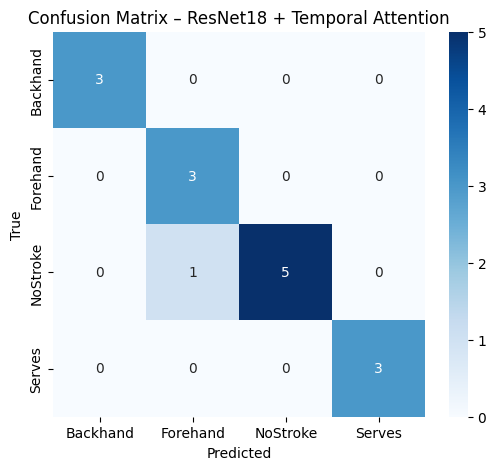

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(test_labels, test_preds)
class_names = ["Backhand", "Forehand", "NoStroke", "Serves"]

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix – ResNet18 + Temporal Attention")
plt.show()

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

report_dict = classification_report(
    test_labels,
    test_preds,
    target_names=class_names,
    output_dict=True
)

df_report = pd.DataFrame(report_dict).transpose()
df_report


,precision,recall,f1-score,support
Backhand,1.000000,1.000000,1.000000,3.000000
Forehand,0.750000,1.000000,0.857143,3.000000
NoStroke,1.000000,0.833333,0.909091,6.000000
Serves,1.000000,1.000000,1.000000,3.000000
accuracy,0.933333,0.933333,0.933333,0.933333
macro avg,0.937500,0.958333,0.941558,15.000000
weighted avg,0.950000,0.933333,0.935065,15.000000


In [ ]:
df_report_rounded = df_report.round(3)
df_report_rounded


,precision,recall,f1-score,support
Backhand,1.000,1.000,1.000,3.000
Forehand,0.750,1.000,0.857,3.000
NoStroke,1.000,0.833,0.909,6.000
Serves,1.000,1.000,1.000,3.000
accuracy,0.933,0.933,0.933,0.933
macro avg,0.938,0.958,0.942,15.000
weighted avg,0.950,0.933,0.935,15.000
